# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Adil Daisuke
- **Email:** ds429b6y0045@student.devacademy.id
- **ID Dicoding:** ds429b6y0045


## Menentukan Pertanyaan Bisnis

Dataset yang dipilih adalah **E-Commerce Public Dataset** (data transaksi marketplace Olist, Brasil). Seluruh analisis dibatasi pada pesanan berstatus `delivered` dengan tanggal pembelian **1 Januari 2017 – 31 Agustus 2018**. Tahun 2016 dan September–Oktober 2018 dikeluarkan karena volumenya sangat kecil dan tidak lengkap, sehingga bisa menyesatkan tren.

**Pertanyaan 1 (Produk & Revenue)**
Pada periode Januari 2017 – Agustus 2018, 10 kategori produk apa yang menghasilkan revenue penjualan terbesar (tanpa ongkos kirim), berapa persen kontribusi masing-masing kategori terhadap total revenue, dan berapa pertumbuhan revenue masing-masing kategori pada Januari–Agustus 2018 dibandingkan Januari–Agustus 2017, **sebagai dasar penentuan kategori prioritas untuk alokasi stok dan anggaran promosi**?

**Pertanyaan 2 (Pengiriman & Kepuasan Pelanggan)**
Pada periode Januari 2017 – Agustus 2018, berapa persen pesanan yang tiba setelah tanggal estimasi, berapa selisih rata-rata review score antara pesanan tepat waktu dan pesanan terlambat, dan 5 state mana (minimal 300 pesanan) yang memiliki persentase keterlambatan tertinggi, **sebagai dasar penentuan wilayah prioritas untuk evaluasi mitra logistik dan perbaikan estimasi pengiriman**?

**Pertanyaan 3 (Perilaku Pelanggan)**
Berdasarkan transaksi Januari 2017 – Agustus 2018, berapa persen pelanggan unik dan berapa persen revenue dari setiap segmen RFM (Recency, Frequency, Monetary), **sebagai dasar pemilihan segmen target dan jenis insentif untuk kampanye retensi**?

| Elemen SMART | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Revenue 10 kategori produk teratas | Keterlambatan pengiriman dan review score per state | Segmen pelanggan berbasis RFM |
| Measurable | Revenue (R$), % kontribusi, % pertumbuhan per kategori | % pesanan terlambat, selisih rata-rata skor, late rate per state | % pelanggan dan % revenue per segmen |
| Action-oriented | Dasar alokasi stok dan anggaran promosi | Dasar evaluasi mitra logistik dan estimasi pengiriman per wilayah | Dasar pemilihan target dan insentif kampanye retensi |
| Relevant | Revenue adalah tujuan utama marketplace | Kepuasan pelanggan menentukan reputasi toko | Retensi lebih murah daripada akuisisi |
| Time-bound | Jan 2017 – Agu 2018 (pertumbuhan: Jan–Agu 2018 vs Jan–Agu 2017) | Jan 2017 – Agu 2018 | Jan 2017 – Agu 2018 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 100})

# Palet konsisten: biru = sorotan utama, abu-abu = pembanding, merah = peringatan/masalah
BLUE, GREY, RED = "#2E5EAA", "#C9CED6", "#D1495B"

## Data Wrangling

### Gathering Data

Tabel yang dipakai: `orders`, `order_items`, `customers`, `products`, `product_category_name_translation`, `order_reviews`, dan `geolocation`. Tabel `order_payments` dan `sellers` tidak dibutuhkan untuk menjawab ketiga pertanyaan, sehingga tidak dimuat. Revenue produk dihitung dari `price` pada `order_items`; nilai belanja pelanggan untuk RFM dihitung dari `price + freight_value`.

In [2]:
DATA = "data/"
orders_df = pd.read_csv(DATA + "orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"])
items_df = pd.read_csv(DATA + "order_items_dataset.csv")
customers_df = pd.read_csv(DATA + "customers_dataset.csv")
products_df = pd.read_csv(DATA + "products_dataset.csv")
translation_df = pd.read_csv(DATA + "product_category_name_translation.csv")
reviews_df = pd.read_csv(DATA + "order_reviews_dataset.csv", parse_dates=["review_answer_timestamp"])
geo_df = pd.read_csv(DATA + "geolocation_dataset.csv")

tables = {"orders": orders_df, "order_items": items_df, "customers": customers_df, "products": products_df,
          "translation": translation_df, "order_reviews": reviews_df, "geolocation": geo_df}
pd.DataFrame({n: d.shape for n, d in tables.items()}, index=["baris", "kolom"]).T

,baris,kolom
orders,99441,8
order_items,112650,7
customers,99441,5
products,32951,9
translation,71,2
order_reviews,99224,7
geolocation,1000163,5


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


**Insight Gathering Data**
- Tujuh tabel berhasil dimuat. Tabel terbesar adalah `geolocation` (±1 juta baris), disusul `order_items` (112.650 baris), `orders` dan `customers` (masing-masing 99.441 baris).
- Relasi antar tabel: `orders`–`order_items`–`order_reviews` lewat `order_id`; `orders`–`customers` lewat `customer_id`; `order_items`–`products` lewat `product_id`; `customers`–`geolocation` lewat zip code prefix.
- Ada 99.441 `customer_id` tetapi hanya 96.096 `customer_unique_id`: satu orang yang berbelanja ulang mendapat `customer_id` baru. Maka **pelanggan unik harus dihitung dengan `customer_unique_id`**, bukan `customer_id`.

### Assessing Data

Setiap tabel dinilai pada aspek: **missing value**, **duplikasi**, **inconsistent/invalid value**, dan **outlier**.

In [4]:
# Ringkasan jumlah baris dan duplikasi semua tabel
pd.DataFrame({"baris": {n: len(d) for n, d in tables.items()},
              "baris_duplikat": {n: d.duplicated().sum() for n, d in tables.items()}})

,baris,baris_duplikat
orders,99441,0
order_items,112650,0
customers,99441,0
products,32951,0
translation,71,0
order_reviews,99224,0
geolocation,1000163,261831


**Missing value per kolom pada setiap tabel** (hanya kolom yang memiliki missing value)

In [5]:
for name, d in tables.items():
    miss = d.isna().sum()
    miss = miss[miss > 0]
    print(f"--- {name} ---")
    print(miss.to_string() if len(miss) else "tidak ada missing value")
    print()

--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

--- order_items ---
tidak ada missing value

--- customers ---
tidak ada missing value

--- products ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

--- translation ---
tidak ada missing value

--- order_reviews ---
review_comment_title      87656
review_comment_message    58247

--- geolocation ---
tidak ada missing value



**Tipe data tabel `orders`**: memastikan kolom tanggal sudah bertipe datetime

In [6]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.0 MB


**Orders: status, rentang waktu, dan konsistensi tanggal**

In [7]:
print(orders_df["order_status"].value_counts().to_string())
print("\nRentang pembelian:", orders_df["order_purchase_timestamp"].min(), "s/d", orders_df["order_purchase_timestamp"].max())
print("\nJumlah pesanan per bulan:")
print(orders_df.groupby(orders_df["order_purchase_timestamp"].dt.to_period("M")).size().to_string())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Rentang pembelian: 2016-09-04 21:15:19 s/d 2018-10-17 17:30:18

Jumlah pesanan per bulan:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


In [8]:
delivered = orders_df[orders_df["order_status"] == "delivered"]
print("Delivered tapi tanggal tiba kosong        :", delivered["order_delivered_customer_date"].isna().sum())
print("Delivered tapi tanggal approve kosong     :", delivered["order_approved_at"].isna().sum())
print("Tanggal kirim ke kurir < tanggal pembelian:", (delivered["order_delivered_carrier_date"] < delivered["order_purchase_timestamp"]).sum())
nd = orders_df[(orders_df["order_status"] != "delivered") & orders_df["order_delivered_customer_date"].notna()]
print("Bukan delivered tapi punya tanggal tiba   :", len(nd), nd["order_status"].value_counts().to_dict())

Delivered tapi tanggal tiba kosong        : 8
Delivered tapi tanggal approve kosong     : 14
Tanggal kirim ke kurir < tanggal pembelian: 165
Bukan delivered tapi punya tanggal tiba   : 6 {'canceled': 6}


**Lama pengiriman dan cakupan review pada pesanan `delivered`**

In [9]:
raw_delivery_days = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.days
print("Statistik lama pengiriman (hari):")
print(raw_delivery_days.describe().round(1).to_string())
print("\nPesanan delivered tanpa review sama sekali:", (~delivered["order_id"].isin(reviews_df["order_id"])).sum())
print("Jam pada tanggal estimasi (unik)          :", orders_df["order_estimated_delivery_date"].dt.time.unique())

Statistik lama pengiriman (hari):
count    96470.0
mean        12.1
std          9.6
min          0.0
25%          6.0
50%         10.0
75%         15.0
max        209.0



Pesanan delivered tanpa review sama sekali: 646
Jam pada tanggal estimasi (unik)          : [datetime.time(0, 0)]


**Order items: outlier pada harga dan ongkir**

In [10]:
for col in ["price", "freight_value"]:
    q1, q3 = items_df[col].quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
    print(f"{col}: median={items_df[col].median():.2f}, max={items_df[col].max():.2f}, batas atas IQR={upper:.2f}, "
          f"jumlah outlier={(items_df[col] > upper).sum()} ({(items_df[col] > upper).mean():.1%})")

price: median=74.99, max=6735.00, batas atas IQR=277.40, jumlah outlier=8427 (7.5%)
freight_value: median=16.26, max=409.68, batas atas IQR=33.25, jumlah outlier=11613 (10.3%)


**Reviews, products, dan customers**

In [11]:
print("Order dengan lebih dari 1 review      :", (reviews_df["order_id"].value_counts() > 1).sum())
print("Distribusi review score               :", reviews_df["review_score"].value_counts().sort_index().to_dict())
print("Produk tanpa kategori                 :", products_df["product_category_name"].isna().sum())
print("Kategori tanpa terjemahan Inggris     :", set(products_df["product_category_name"].dropna()) - set(translation_df["product_category_name"]))
print("customer_id unik vs customer_unique_id:", customers_df["customer_id"].nunique(), "vs", customers_df["customer_unique_id"].nunique())

Order dengan lebih dari 1 review      : 547
Distribusi review score               : {1: 11424, 2: 3151, 3: 8179, 4: 19142, 5: 57328}
Produk tanpa kategori                 : 610
Kategori tanpa terjemahan Inggris     : {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}
customer_id unik vs customer_unique_id: 99441 vs 96096


**Geolocation: duplikasi dan koordinat di luar Brasil**

In [12]:
in_brazil = geo_df["geolocation_lat"].between(-33.8, 5.3) & geo_df["geolocation_lng"].between(-73.9, -34.7)
print("Baris duplikat penuh                       :", geo_df.duplicated().sum())
print("Jumlah zip prefix unik                     :", geo_df["geolocation_zip_code_prefix"].nunique(), "dari", len(geo_df), "baris")
print("Koordinat di luar kotak batas Brasil       :", (~in_brazil).sum())
print("Zip pelanggan yang tidak ada di geolocation:", (~customers_df["customer_zip_code_prefix"].isin(geo_df["geolocation_zip_code_prefix"])).sum())

Baris duplikat penuh                       : 261831
Jumlah zip prefix unik                     : 19015 dari 1000163 baris
Koordinat di luar kotak batas Brasil       : 42
Zip pelanggan yang tidak ada di geolocation: 278


**Insight Assessing Data: masalah yang ditemukan dan rencana cleaning**

Semua angka di tabel ini berasal dari output sel-sel Assessing di atas.

| Jenis masalah | Temuan | Tindakan di tahap Cleaning |
|---|---|---|
| Missing value | `products`: 610 produk tanpa kategori. `orders`: `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965) kosong; 8 pesanan `delivered` tidak punya tanggal tiba. 646 pesanan `delivered` tidak punya review sama sekali | Kategori kosong diberi label `unknown`. Tanggal kosong umumnya karena pesanan belum/tidak terkirim (status selain `delivered`), sehingga tersaring oleh filter status; 8 pesanan delivered tanpa tanggal tiba dikeluarkan. Pesanan tanpa review tetap dipakai untuk analisis revenue dan otomatis diabaikan saat menghitung rata-rata review |
| Duplicate data | `geolocation`: 261.831 baris duplikat penuh dan hanya 19.015 zip prefix unik dari ±1 juta baris; 547 order punya lebih dari satu review | Geolokasi diringkas menjadi satu titik (rata-rata lat/lng) per zip prefix; review dipertahankan satu per order (yang terbaru) |
| Inconsistent value | 165 pesanan `delivered` dengan tanggal kirim ke kurir lebih awal dari tanggal pembelian; 6 pesanan `canceled` punya tanggal tiba; 2 kategori produk tanpa terjemahan Inggris; tanggal estimasi hanya berisi tanggal (jam 00:00) sedangkan tanggal tiba berisi jam | Kolom tanggal kurir tidak dipakai; pesanan batal tersaring oleh filter status; terjemahan ditambahkan manual; keterlambatan dihitung pada level tanggal |
| Invalid / inaccurate value | 42 koordinat geolokasi berada di luar Brasil; 278 zip pelanggan tidak ada di tabel geolokasi | Koordinat di luar Brasil dibuang; zip tanpa koordinat hanya dikecualikan dari peta |
| Outlier | Harga: 8.427 item (7,5%) di atas batas IQR R$ 277,40 (maks R$ 6.735); ongkir: 11.613 item (10,3%); lama pengiriman maksimum 209 hari (median 10 hari) | Dipertahankan karena nilai nyata (barang mahal, pengiriman jauh); ringkasan lama pengiriman memakai median |
| Cakupan waktu | 2016 hanya 329 pesanan; Sep-Okt 2018 hanya 20 pesanan | Analisis dibatasi Jan 2017 - Agu 2018 agar tren tidak bias |

### Cleaning Data

Setiap masalah dari tahap Assessing ditangani satu per satu, lalu diverifikasi dengan pengecekan sebelum-sesudah.

**1. Kategori produk: isi missing value dan lengkapi terjemahan yang hilang**

In [13]:
# 610 produk tanpa kategori diberi label "unknown"; 2 kategori tanpa terjemahan ditambahkan manual
extra = pd.DataFrame({"product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
                      "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers", "unknown"]})
translation_clean = pd.concat([translation_df, extra], ignore_index=True)

products_clean = products_df.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")
products_clean = products_clean.merge(translation_clean, on="product_category_name", how="left")

print("Kategori Inggris yang masih kosong:", products_clean["product_category_name_english"].isna().sum())

Kategori Inggris yang masih kosong: 0


**2. Review: satu review per order (ambil yang terbaru)**

In [14]:
reviews_clean = (reviews_df.sort_values("review_answer_timestamp")
                 .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])
print("Order dengan >1 review setelah cleaning:", (reviews_clean["order_id"].value_counts() > 1).sum())

Order dengan >1 review setelah cleaning: 0


**3. Geolocation: buang koordinat di luar Brasil, lalu ringkas menjadi satu titik per zip prefix**

In [15]:
geo_clean = (geo_df[in_brazil].groupby("geolocation_zip_code_prefix")
             .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean")).reset_index())
print("Baris sebelum:", len(geo_df), "-> sesudah:", len(geo_clean), "| duplikat zip:", geo_clean["geolocation_zip_code_prefix"].duplicated().sum())

Baris sebelum: 1000163 -> sesudah: 19010 | duplikat zip: 0


**4. Orders: hanya pesanan `delivered` dengan tanggal tiba valid, pada periode Jan 2017 – Agu 2018**

Langkah ini sekaligus menyingkirkan 8 pesanan delivered tanpa tanggal tiba dan 6 pesanan batal yang punya tanggal tiba. Kolom turunan:
- `delivery_days`: lama pengiriman (hari) dari pembelian sampai tiba.
- `delay_days`: **tanggal** tiba dikurangi **tanggal** estimasi (positif = terlambat). Tanggal estimasi hanya berisi tanggal (jam selalu 00:00), sehingga perbandingan dilakukan pada level tanggal agar pesanan yang tiba *pada* hari estimasi tidak dihitung terlambat.
- `is_late`: 1 jika `delay_days > 0`. Dengan begitu definisi terlambat konsisten dengan binning keterlambatan di tahap EDA.

In [16]:
orders_clean = orders_df[(orders_df["order_status"] == "delivered")
                         & orders_df["order_delivered_customer_date"].notna()
                         & (orders_df["order_purchase_timestamp"] >= "2017-01-01")
                         & (orders_df["order_purchase_timestamp"] < "2018-09-01")].copy()

orders_clean["delivery_days"] = (orders_clean["order_delivered_customer_date"] - orders_clean["order_purchase_timestamp"]).dt.days
orders_clean["delay_days"] = (orders_clean["order_delivered_customer_date"].dt.normalize()
                              - orders_clean["order_estimated_delivery_date"].dt.normalize()).dt.days
orders_clean["is_late"] = (orders_clean["delay_days"] > 0).astype(int)

print("Pesanan sebelum:", len(orders_df), "-> sesudah:", len(orders_clean))
print("Status tersisa:", list(orders_clean["order_status"].unique()))
print("\nCek ulang missing value kolom tanggal setelah cleaning:")
print(orders_clean[["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]].isna().sum().to_string())
print("\nStatistik lama pengiriman setelah cleaning (hari):")
print(orders_clean["delivery_days"].describe().round(1).to_string())

Pesanan sebelum: 99441 -> sesudah: 96203
Status tersisa: ['delivered']

Cek ulang missing value kolom tanggal setelah cleaning:
order_purchase_timestamp         0
order_delivered_customer_date    0
order_estimated_delivery_date    0

Statistik lama pengiriman setelah cleaning (hari):
count    96203.0
mean        12.1
std          9.5
min          0.0
25%          6.0
50%         10.0
75%         15.0
max        209.0


**5. Outlier harga dan lama pengiriman: dipertahankan**

Harga tinggi (hingga R$ 6.735) adalah produk nyata, bukan kesalahan input, dan pengiriman yang sangat lama (maksimum 209 hari, median 10 hari, lihat output statistik lama pengiriman di atas) adalah kejadian nyata yang justru relevan untuk analisis keterlambatan. Penanganannya adalah memakai **median** untuk ringkasan lama pengiriman, dan tidak membuang baris.

**6. Menggabungkan tabel menjadi satu tabel analisis (`main_df`) dan menyimpannya untuk dashboard**

In [17]:
order_cols = ["order_id", "customer_unique_id", "order_purchase_timestamp", "customer_state",
              "delivery_days", "delay_days", "is_late", "review_score", "lat", "lng"]

orders_full = (orders_clean.merge(customers_df, on="customer_id", how="left")
               .merge(reviews_clean, on="order_id", how="left")
               .merge(geo_clean, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left"))

main_df = (items_df[["order_id", "product_id", "price", "freight_value"]]
           .merge(orders_full[order_cols], on="order_id", how="inner")
           .merge(products_clean[["product_id", "product_category_name_english"]], on="product_id", how="left")
           .rename(columns={"product_category_name_english": "product_category"})
           .drop(columns="product_id"))

main_df["order_purchase_timestamp"] = main_df["order_purchase_timestamp"].dt.strftime("%Y-%m-%d")
main_df[["lat", "lng"]] = main_df[["lat", "lng"]].round(4)
main_df["order_purchase_timestamp"] = pd.to_datetime(main_df["order_purchase_timestamp"])
print(main_df.shape)
main_df.isna().sum()

(109872, 13)


order_id                      0
price                         0
freight_value                 0
customer_unique_id            0
order_purchase_timestamp      0
customer_state                0
delivery_days                 0
delay_days                    0
is_late                       0
review_score                823
lat                         289
lng                         289
product_category              0
dtype: int64

In [18]:
# Disimpan untuk dashboard (satu baris = satu item pesanan)
main_df.to_csv("dashboard/main_data.csv", index=False)
main_df.head()

,order_id,price,freight_value,customer_unique_id,order_purchase_timestamp,customer_state,delivery_days,delay_days,is_late,review_score,lat,lng,product_category
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,871766c5855e863f6eccc05f988b23cb,2017-09-13,RJ,7,-9,0,5.0,-21.7628,-41.3096,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,eb28e67c4c0b83846050ddfb8a35d051,2017-04-26,SP,16,-3,0,4.0,-20.2205,-50.9034,pet_shop
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,3818d81c6709e39d06b2738a8d3a2474,2018-01-14,MG,7,-14,0,5.0,-19.8703,-44.5933,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,af861d436cfc08b2c2ddefd0ba074622,2018-08-08,SP,6,-6,0,4.0,-23.0899,-46.6117,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,64b576fb70d441e8f1b2d7d446e483c5,2017-02-04,SP,25,-16,0,5.0,-23.2434,-46.8276,garden_tools


**Insight Cleaning Data**
- Setelah cleaning tersisa **96.203 pesanan `delivered`**, **109.872 baris item**, **93.096 pelanggan unik**, dan **74 kategori produk** pada periode 5 Jan 2017 - 29 Agu 2018.
- Semua masalah pada tahap Assessing sudah tertangani dan diverifikasi ulang: tidak ada lagi kategori kosong, tidak ada order dengan lebih dari satu review, tidak ada duplikasi zip pada geolokasi, dan kolom tanggal yang dipakai tidak lagi memiliki missing value.
- Sisa missing value yang disengaja: 823 baris item tanpa review dan 289 baris tanpa koordinat. Keduanya kecil (<1%) dan tidak memengaruhi kesimpulan.
- Hasilnya disimpan sebagai `dashboard/main_data.csv` (satu baris = satu item pesanan) untuk dipakai dashboard.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data Umum

In [19]:
order_df = main_df.drop_duplicates("order_id")   # satu baris = satu pesanan (untuk metrik level pesanan)
print("Jumlah pesanan        :", order_df["order_id"].nunique())
print("Jumlah pelanggan unik :", main_df["customer_unique_id"].nunique())
print("Jumlah kategori       :", main_df["product_category"].nunique())
print("Total revenue produk  : R$ {:,.0f}".format(main_df["price"].sum()))
print("Periode               :", main_df["order_purchase_timestamp"].min().date(), "s/d", main_df["order_purchase_timestamp"].max().date())
main_df[["price", "freight_value"]].describe().round(2)

Jumlah pesanan        : 96203
Jumlah pelanggan unik : 93096
Jumlah kategori       : 74
Total revenue produk  : R$ 13,179,778
Periode               : 2017-01-05 s/d 2018-08-29


,price,freight_value
count,109872.00,109872.00
mean,119.96,19.95
std,182.35,15.70
min,0.85,0.00
25%,39.90,13.08
50%,74.90,16.26
75%,134.04,21.15
max,6735.00,409.68


### Eksplorasi Pertanyaan 1: Kategori Produk dan Revenue

In [20]:
cat_rev = (main_df.groupby("product_category")
           .agg(revenue=("price", "sum"), items=("price", "size"), orders=("order_id", "nunique"))
           .sort_values("revenue", ascending=False))
cat_rev["share_pct"] = cat_rev["revenue"] / cat_rev["revenue"].sum() * 100
cat_rev["cum_share_pct"] = cat_rev["share_pct"].cumsum()
top10 = cat_rev.head(10).copy()
print("Kontribusi 10 kategori teratas: {:.1f}% dari total revenue ({} kategori)".format(top10["share_pct"].sum(), len(cat_rev)))
top10.round(1)

Kontribusi 10 kategori teratas: 62.5% dari total revenue (74 kategori)


,revenue,items,orders,share_pct,cum_share_pct
product_category,,,,,
health_beauty,1229557.5,9422,8610,9.3,9.3
watches_gifts,1163187.9,5853,5489,8.8,18.2
bed_bath_table,1022955.8,10945,9267,7.8,25.9
sports_leisure,952661.4,8413,7512,7.2,33.1
computers_accessories,887944.6,7631,6517,6.7,39.9
furniture_decor,706237.2,8095,6258,5.4,45.2
housewares,614341.6,6783,5734,4.7,49.9
cool_stuff,609158.0,3711,3552,4.6,54.5
auto,577721.1,4131,3801,4.4,58.9


In [21]:
# Pertumbuhan Jan-Agu 2018 vs Jan-Agu 2017 (jendela 8 bulan yang sama agar adil)
d = main_df["order_purchase_timestamp"]
rev_2017 = main_df[(d >= "2017-01-01") & (d < "2017-09-01")].groupby("product_category")["price"].sum()
rev_2018 = main_df[(d >= "2018-01-01") & (d < "2018-09-01")].groupby("product_category")["price"].sum()
growth = pd.DataFrame({"rev_2017": rev_2017, "rev_2018": rev_2018})
growth["growth_pct"] = (growth["rev_2018"] / growth["rev_2017"] - 1) * 100
top10 = top10.join(growth)
top10[["revenue", "share_pct", "rev_2017", "rev_2018", "growth_pct"]].round(1)

,revenue,share_pct,rev_2017,rev_2018,growth_pct
product_category,,,,,
health_beauty,1229557.5,9.3,243521.7,755724.5,210.3
watches_gifts,1163187.9,8.8,201137.9,687577.2,241.8
bed_bath_table,1022955.8,7.8,254444.8,532358.8,109.2
sports_leisure,952661.4,7.2,216545.3,517166.3,138.8
computers_accessories,887944.6,6.7,214631.3,496158.3,131.2
furniture_decor,706237.2,5.4,170858.6,381649.6,123.4
housewares,614341.6,4.7,127534.5,391823.5,207.2
cool_stuff,609158.0,4.6,206306.4,227743.7,10.4
auto,577721.1,4.4,125247.5,343288.3,174.1


In [22]:
monthly = main_df.groupby(main_df["order_purchase_timestamp"].dt.to_period("M")).agg(
    revenue=("price", "sum"), orders=("order_id", "nunique"))
monthly.index = monthly.index.to_timestamp()
monthly["revenue_mom_pct"] = monthly["revenue"].pct_change() * 100
print("Revenue Jan-Agu 2017: R$ {:,.0f} | Jan-Agu 2018: R$ {:,.0f} | growth: {:.0f}%".format(
    monthly.loc["2017-01":"2017-08", "revenue"].sum(), monthly.loc["2018-01":"2018-08", "revenue"].sum(),
    (monthly.loc["2018-01":"2018-08", "revenue"].sum() / monthly.loc["2017-01":"2017-08", "revenue"].sum() - 1) * 100))
print("Bulan revenue tertinggi:", monthly["revenue"].idxmax().strftime("%b %Y"), "- R$ {:,.0f}".format(monthly["revenue"].max()))
monthly.round(1)

Revenue Jan-Agu 2017: R$ 2,993,277 | Jan-Agu 2018: R$ 7,217,172 | growth: 141%
Bulan revenue tertinggi: Nov 2017 - R$ 987,648


,revenue,orders,revenue_mom_pct
order_purchase_timestamp,,,
2017-01-01,111798.4,750,NaN
2017-02-01,234223.4,1653,109.5
2017-03-01,359198.8,2546,53.4
2017-04-01,340669.7,2303,-5.2
2017-05-01,489159.2,3545,43.6
2017-06-01,421923.4,3135,-13.7
2017-07-01,481604.5,3872,14.1
2017-08-01,554699.7,4193,15.2
2017-09-01,607399.7,4150,9.5


**Insight EDA Pertanyaan 1**
- Total revenue produk periode ini **R$ 13,18 juta** dari 96.203 pesanan.
- **10 kategori teratas menyumbang 62,5%** revenue dari 74 kategori: `health_beauty` 9,3%, `watches_gifts` 8,8%, `bed_bath_table` 7,8%, `sports_leisure` 7,2%, `computers_accessories` 6,7%, `furniture_decor` 5,4%, `housewares` 4,7%, `cool_stuff` 4,6%, `auto` 4,4%, dan `garden_tools` 3,6%.
- Jumlah item tidak sama dengan revenue: `bed_bath_table` terjual paling banyak (10.945 item) tetapi rata-rata harga per item sekitar R$ 93, sedangkan `watches_gifts` hanya 5.853 item dengan rata-rata sekitar R$ 199.
- Revenue Jan-Agu 2018 (R$ 7,22 juta) naik **141%** dibanding Jan-Agu 2017 (R$ 2,99 juta). Pertumbuhan tertinggi: `watches_gifts` +242%, `health_beauty` +210%, `housewares` +207%. Tertinggal: `cool_stuff` hanya +10% dan `garden_tools` +54%.
- Revenue bulanan memuncak pada **Nov 2017 (R$ 987.648, naik 52% dari bulan sebelumnya)**, lalu mendatar di kisaran R$ 0,83-0,98 juta sepanjang 2018.

### Eksplorasi Pertanyaan 2: Keterlambatan Pengiriman dan Review Score

In [23]:
late_rate = order_df["is_late"].mean() * 100
by_late = order_df.groupby("is_late")["review_score"].agg(["mean", "count"]).rename(index={0: "Tepat waktu", 1: "Terlambat"})
low_score = order_df.groupby("is_late")["review_score"].apply(lambda s: (s <= 2).mean() * 100)
by_late["pct_skor_1_2"] = low_score.values
print("Persentase pesanan terlambat: {:.2f}%".format(late_rate))
print("Selisih rata-rata review: {:.2f} poin".format(by_late.loc["Tepat waktu", "mean"] - by_late.loc["Terlambat", "mean"]))
by_late.round(2)

Persentase pesanan terlambat: 6.79%
Selisih rata-rata review: 2.02 poin


,mean,count,pct_skor_1_2
is_late,,,
Tepat waktu,4.29,89182,9.20
Terlambat,2.27,6378,60.96


In [24]:
state_df = (order_df.groupby("customer_state")
            .agg(orders=("order_id", "nunique"), late_rate=("is_late", "mean"),
                 avg_review=("review_score", "mean"), median_delivery_days=("delivery_days", "median"))
            .assign(late_rate=lambda x: x["late_rate"] * 100))
state_eligible = state_df[state_df["orders"] >= 300].sort_values("late_rate", ascending=False)
print("State yang memenuhi syarat (>=300 pesanan):", len(state_eligible), "dari", len(state_df))
state_eligible.round(2).head(10)

State yang memenuhi syarat (>=300 pesanan): 21 dari 27


,orders,late_rate,avg_review,median_delivery_days
customer_state,,,,
AL,396,21.46,3.85,22.0
MA,713,17.53,3.83,19.0
SE,332,15.36,3.90,17.0
PI,475,13.89,3.99,16.0
CE,1273,13.83,3.94,18.0
BA,3253,12.17,3.93,16.0
RJ,12310,12.14,3.97,12.0
PA,942,11.25,3.91,21.0
ES,1992,10.74,4.08,13.0


**Binning keterlambatan.** Selisih tanggal tiba dan tanggal estimasi dikelompokkan ke dalam interval (binning). Keterlambatan 1 hari dipisahkan sendiri agar efek hari pertama terlambat dapat dilihat.

In [25]:
delay_bins = [-np.inf, -8, -1, 0, 1, 3, 7, np.inf]
delay_labels = ["Lebih awal >7 hari", "Lebih awal 1-7 hari", "Hari estimasi", "Telat 1 hari", "Telat 2-3 hari", "Telat 4-7 hari", "Telat >7 hari"]
order_df = order_df.assign(delay_group=pd.cut(order_df["delay_days"], bins=delay_bins, labels=delay_labels))
delay_summary = (order_df.groupby("delay_group", observed=True)["review_score"]
                 .agg(avg_review="mean", orders="count").round(2))
delay_summary

,avg_review,orders
delay_group,,
Lebih awal >7 hari,4.32,70673
Lebih awal 1-7 hari,4.20,17229
Hari estimasi,4.03,1280
Telat 1 hari,3.73,819
Telat 2-3 hari,2.94,1032
Telat 4-7 hari,2.10,1748
Telat >7 hari,1.70,2779


**Insight EDA Pertanyaan 2**
- **6,79% pesanan tiba setelah tanggal estimasi.** Rata-rata review pesanan tepat waktu **4,29** vs **2,27** untuk pesanan terlambat: selisih **2,02 poin**. Pada pesanan terlambat, 61,0% memberi skor 1-2, sedangkan pada pesanan tepat waktu hanya 9,2%.
- 5 state dengan late rate tertinggi (minimal 300 pesanan): **AL 21,5%, MA 17,5%, SE 15,4%, PI 13,9%, CE 13,8%**. Semuanya di Timur Laut, dengan median lama pengiriman 16-22 hari. RJ perlu perhatian khusus karena volumenya besar (12.310 pesanan) dengan late rate 12,1%.
- Binning menunjukkan rata-rata review sudah sedikit menurun sebelum estimasi terlewati (4,32 → 4,20 → 4,03 pada hari estimasi). Setelah estimasi terlewati, penurunannya jauh lebih besar: **3,73 pada telat 1 hari**, 2,94 pada telat 2-3 hari, 2,10 pada telat 4-7 hari, dan 1,70 pada telat lebih dari 7 hari.

### Eksplorasi Pertanyaan 3: Segmentasi Pelanggan (RFM)

Skor R dan M dibuat dengan membagi pelanggan ke 5 kelompok sama besar (kuintil; skor 5 = terbaik). Skor F **tidak** memakai kuintil karena ±97% pelanggan hanya belanja sekali, sehingga F dikelompokkan manual: 1 pesanan = skor 1, 2 pesanan = skor 3, 3+ pesanan = skor 5. Segmen ditentukan dengan aturan bisnis berikut:

| Segmen | Aturan |
|---|---|
| Repeat Buyers | Frequency ≥ 2 |
| New High-Value | 1 pesanan, R score ≥ 4 (baru belanja), M score ≥ 4 (40% belanja terbesar) |
| New Customers | 1 pesanan, R score ≥ 4, M score ≤ 3 |
| Cooling Down | 1 pesanan, R score = 3 |
| Dormant High-Value | 1 pesanan, R score ≤ 2 (lama tidak belanja), M score ≥ 4 |
| Lost / Low-Value | 1 pesanan, R score ≤ 2, M score ≤ 3 |

In [26]:
cust = (main_df.groupby("customer_unique_id")
        .agg(last_purchase=("order_purchase_timestamp", "max"), frequency=("order_id", "nunique"),
             price_sum=("price", "sum"), freight_sum=("freight_value", "sum")))
cust["monetary"] = cust["price_sum"] + cust["freight_sum"]
snapshot = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
cust["recency"] = (snapshot - cust["last_purchase"]).dt.days

cust["R_score"] = pd.qcut(cust["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
cust["M_score"] = pd.qcut(cust["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
cust["F_score"] = pd.cut(cust["frequency"], [0, 1, 2, np.inf], labels=[1, 3, 5]).astype(int)

def segment(r):
    if r["frequency"] >= 2: return "Repeat Buyers"
    if r["R_score"] >= 4:   return "New High-Value" if r["M_score"] >= 4 else "New Customers"
    if r["R_score"] == 3:   return "Cooling Down"
    return "Dormant High-Value" if r["M_score"] >= 4 else "Lost / Low-Value"

cust["segment"] = cust.apply(segment, axis=1)
print("Snapshot date:", snapshot.date(), "| pelanggan unik:", len(cust))
print("Pelanggan dengan >=2 pesanan: {:.1f}%".format((cust["frequency"] >= 2).mean() * 100))
cust[["recency", "frequency", "monetary"]].describe().round(1)

Snapshot date: 2018-08-30 | pelanggan unik: 93096
Pelanggan dengan >=2 pesanan: 3.0%


,recency,frequency,monetary
count,93096.0,93096.0,93096.0
mean,237.2,1.0,165.1
std,150.9,0.2,226.4
min,1.0,1.0,9.6
25%,115.0,1.0,63.0
50%,219.0,1.0,107.8
75%,346.0,1.0,182.4
max,602.0,15.0,13664.1


In [27]:
seg = (cust.groupby("segment")
       .agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
            avg_recency=("recency", "mean"), avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean")))
seg["pct_customers"] = seg["customers"] / seg["customers"].sum() * 100
seg["pct_revenue"] = seg["revenue"] / seg["revenue"].sum() * 100
seg_order = ["New High-Value", "Dormant High-Value", "Cooling Down", "New Customers", "Lost / Low-Value", "Repeat Buyers"]
seg = seg.loc[seg_order]
seg.round(1)

,customers,revenue,avg_recency,avg_frequency,avg_monetary,pct_customers,pct_revenue
segment,,,,,,,
New High-Value,14377,4342485.4,91.7,1.0,302.0,15.4,28.2
Dormant High-Value,13733,4221052.1,391.5,1.0,307.4,14.8,27.5
Cooling Down,18018,2732241.6,219.9,1.0,151.6,19.4,17.8
New Customers,21665,1579000.1,90.1,1.0,72.9,23.3,10.3
Lost / Low-Value,22514,1636428.6,393.7,1.0,72.7,24.2,10.6
Repeat Buyers,2789,860533.2,220.1,2.1,308.5,3.0,5.6


**Insight EDA Pertanyaan 3**
- Hanya **3,0% pelanggan unik** (2.789 dari 93.096) yang berbelanja lebih dari sekali; median recency 219 hari dan median monetary R$ 107,8.
- Persen pelanggan vs persen revenue per segmen: **New High-Value** 15,4% pelanggan / 28,2% revenue; **Dormant High-Value** 14,8% / 27,5%; **Cooling Down** 19,4% / 17,8%; **New Customers** 23,3% / 10,3%; **Lost / Low-Value** 24,2% / 10,6%; **Repeat Buyers** 3,0% / 5,6%.
- Dua segmen high-value memiliki rata-rata belanja sekitar R$ 300 per pelanggan, empat kali lipat New Customers dan Lost / Low-Value (sekitar R$ 73).

## Visualization & Explanatory Analysis

### Pertanyaan 1: 10 kategori produk dengan revenue terbesar dan pertumbuhannya

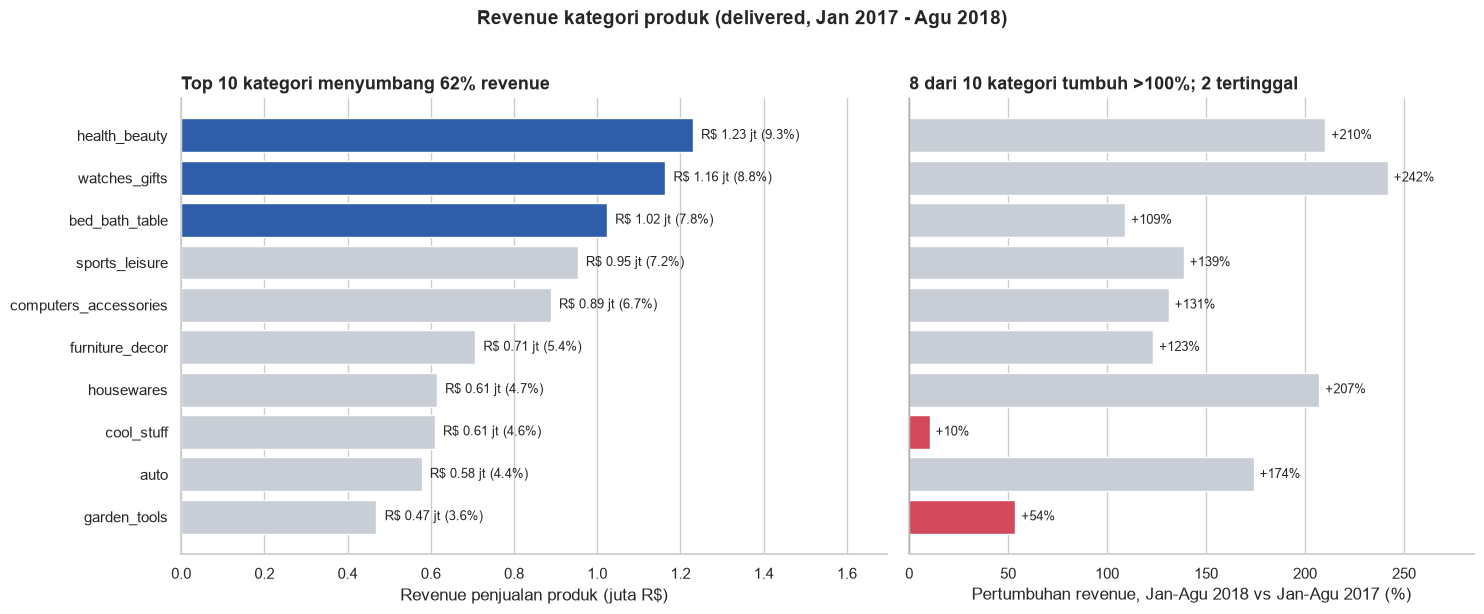

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.25, 1]})
plot_df = top10.iloc[::-1]
colors = [BLUE if i >= 7 else GREY for i in range(10)]   # 3 kategori teratas disorot

ax = axes[0]
ax.barh(plot_df.index, plot_df["revenue"] / 1e6, color=colors)
for y, (rev, share) in enumerate(zip(plot_df["revenue"] / 1e6, plot_df["share_pct"])):
    ax.text(rev + 0.02, y, f"R$ {rev:.2f} jt ({share:.1f}%)", va="center", fontsize=9)
ax.set_xlim(0, plot_df["revenue"].max() / 1e6 * 1.38)
ax.set_xlabel("Revenue penjualan produk (juta R$)"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
ax.set_title("Top 10 kategori menyumbang {:.0f}% revenue".format(top10["share_pct"].sum()), loc="left")

ax = axes[1]
g = plot_df["growth_pct"]
ax.barh(plot_df.index, g, color=[RED if v < 100 else GREY for v in g])   # merah = tumbuh <100%
for y, v in enumerate(g):
    ax.text(v + 3, y, f"+{v:.0f}%", va="center", fontsize=9)
ax.set_yticklabels([]); ax.set_xlim(0, g.max() * 1.18)
ax.set_xlabel("Pertumbuhan revenue, Jan-Agu 2018 vs Jan-Agu 2017 (%)")
ax.set_title("8 dari 10 kategori tumbuh >100%; 2 tertinggal", loc="left")
ax.grid(axis="y", visible=False)
ax.axvline(0, color="black", lw=0.8)

fig.suptitle("Revenue kategori produk (delivered, Jan 2017 - Agu 2018)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

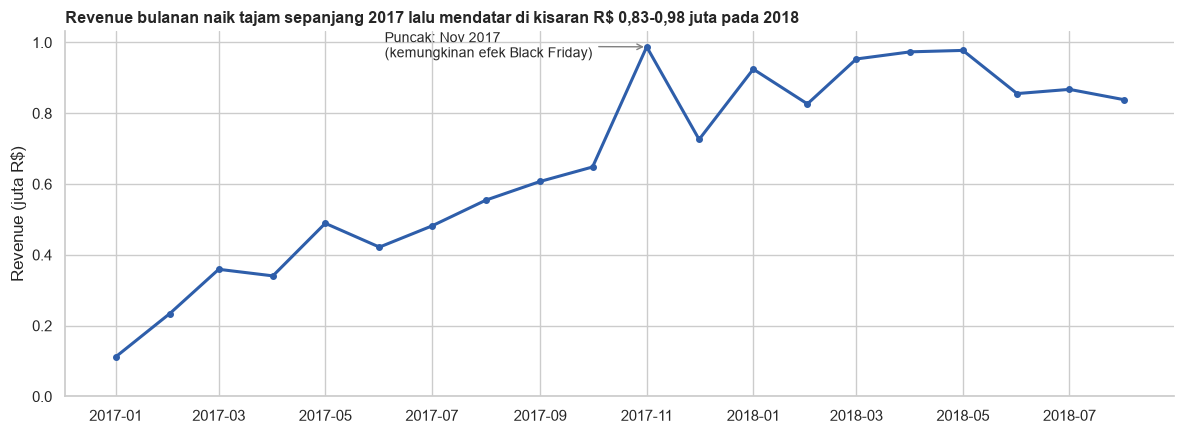

In [29]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly["revenue"] / 1e6, color=BLUE, lw=2.2, marker="o", ms=4)
peak = monthly["revenue"].idxmax()
ax.annotate("Puncak: Nov 2017\n(kemungkinan efek Black Friday)", xy=(peak, monthly["revenue"].max() / 1e6),
            xytext=(peak - pd.Timedelta(days=150), monthly["revenue"].max() / 1e6 * 0.97),
            arrowprops=dict(arrowstyle="->", color="grey"), fontsize=10)
ax.set_ylim(0, None); ax.set_ylabel("Revenue (juta R$)"); ax.set_xlabel("")
ax.set_title("Revenue bulanan naik tajam sepanjang 2017 lalu mendatar di kisaran R$ 0,83-0,98 juta pada 2018", loc="left", fontsize=11.5)
plt.tight_layout(); plt.show()

**Insight Visualisasi Pertanyaan 1**
- Revenue sangat terkonsentrasi: 10 dari 74 kategori menguasai 62,5% penjualan, dan lima teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) saja menyumbang 39,9%.
- 8 dari 10 kategori teratas tumbuh di atas 100% pada Jan-Agu 2018 dibanding periode yang sama 2017. Dua kategori tertinggal, yaitu `cool_stuff` (+10%) dan `garden_tools` (+54%).
- Tren bulanan menunjukkan pertumbuhan pesat sepanjang 2017 dan lonjakan November 2017, tetapi revenue 2018 mendatar: pertumbuhan awal belum berlanjut menjadi kenaikan bulanan yang konsisten.

### Pertanyaan 2: keterlambatan pengiriman, review score, dan wilayah bermasalah

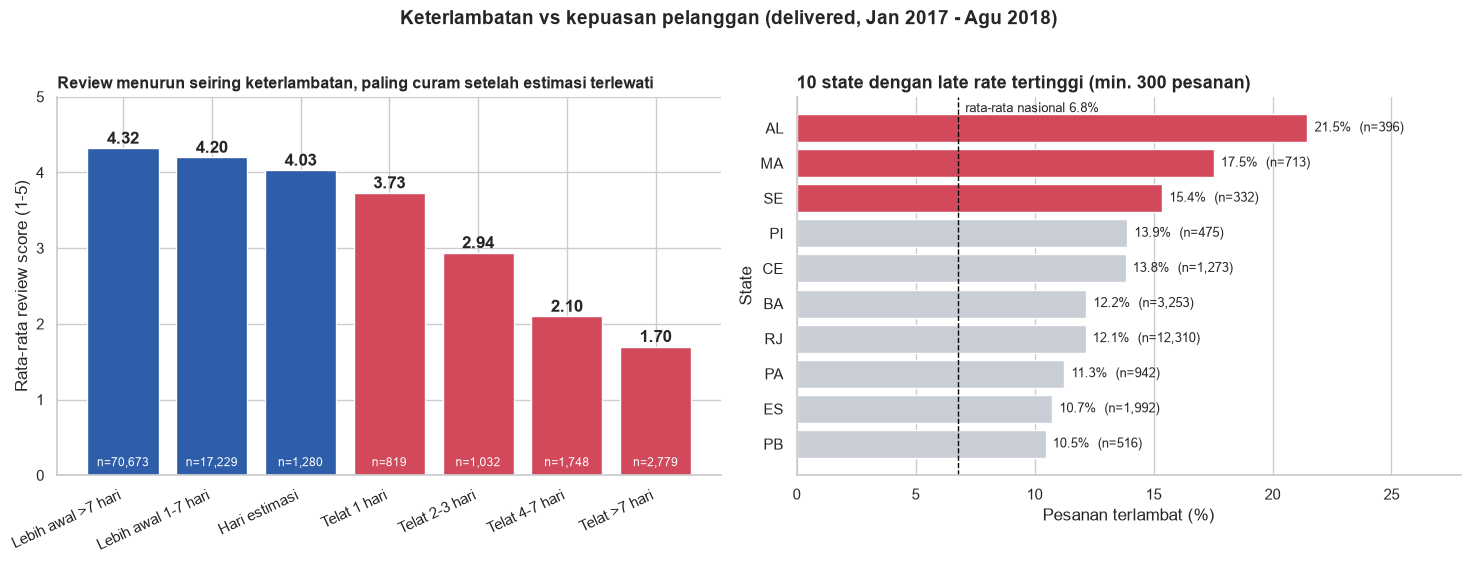

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ds = delay_summary.reset_index()
bar_colors = [BLUE if "awal" in l or l == "Hari estimasi" else RED for l in ds["delay_group"]]
ax.bar(ds["delay_group"], ds["avg_review"], color=bar_colors)
for x, (v, n) in enumerate(zip(ds["avg_review"], ds["orders"])):
    ax.text(x, v + 0.06, f"{v:.2f}", ha="center", fontweight="bold")
    ax.text(x, 0.12, f"n={n:,}", ha="center", color="white", fontsize=8.5)
ax.set_ylim(0, 5); ax.set_ylabel("Rata-rata review score (1-5)"); ax.set_xlabel("")
ax.set_xticks(range(len(ds))); ax.set_xticklabels(ds["delay_group"], rotation=25, ha="right")
ax.set_title("Review menurun seiring keterlambatan, paling curam setelah estimasi terlewati", loc="left", fontsize=11.5)

ax = axes[1]
top_late = state_eligible.head(10).iloc[::-1]
ax.barh(top_late.index, top_late["late_rate"], color=[RED if i >= 7 else GREY for i in range(len(top_late))])   # 3 state teratas disorot
for y, (v, n) in enumerate(zip(top_late["late_rate"], top_late["orders"])):
    ax.text(v + 0.3, y, f"{v:.1f}%  (n={n:,})", va="center", fontsize=9)
ax.axvline(late_rate, color="black", ls="--", lw=1)
ax.text(late_rate + 0.3, 9.45, f"rata-rata nasional {late_rate:.1f}%", fontsize=9)
ax.set_xlim(0, top_late["late_rate"].max() * 1.3)
ax.set_xlabel("Pesanan terlambat (%)"); ax.set_ylabel("State"); ax.grid(axis="y", visible=False)
ax.set_title("10 state dengan late rate tertinggi (min. 300 pesanan)", loc="left")

fig.suptitle("Keterlambatan vs kepuasan pelanggan (delivered, Jan 2017 - Agu 2018)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Insight Visualisasi Pertanyaan 2**
- Rata-rata review menurun bertahap seiring makin lambatnya pesanan tiba relatif terhadap estimasi. Sebelum estimasi terlewati penurunannya kecil (4,32 → 4,20 → 4,03), sedangkan setelah terlewati penurunannya jauh lebih curam: 3,73 (telat 1 hari), 2,94 (telat 2-3 hari), 2,10 (telat 4-7 hari), hingga 1,70 (telat >7 hari).
- Keterlambatan terkonsentrasi di wilayah tertentu: lima state teratas (AL, MA, SE, PI, CE) memiliki late rate 13,8-21,5%, dua sampai tiga kali rata-rata nasional 6,8%.
- Catatan interpretasi: ini hanya hubungan (korelasi) dari agregasi, bukan bukti sebab-akibat. Keterlambatan **berkaitan dengan** review yang jauh lebih rendah, tetapi analisis ini tidak membandingkan faktor lain (kualitas produk, penjual, harga) sehingga tidak dapat disimpulkan sebagai penyebab utama ketidakpuasan.

### Pertanyaan 3: segmentasi pelanggan RFM dan prioritas retensi

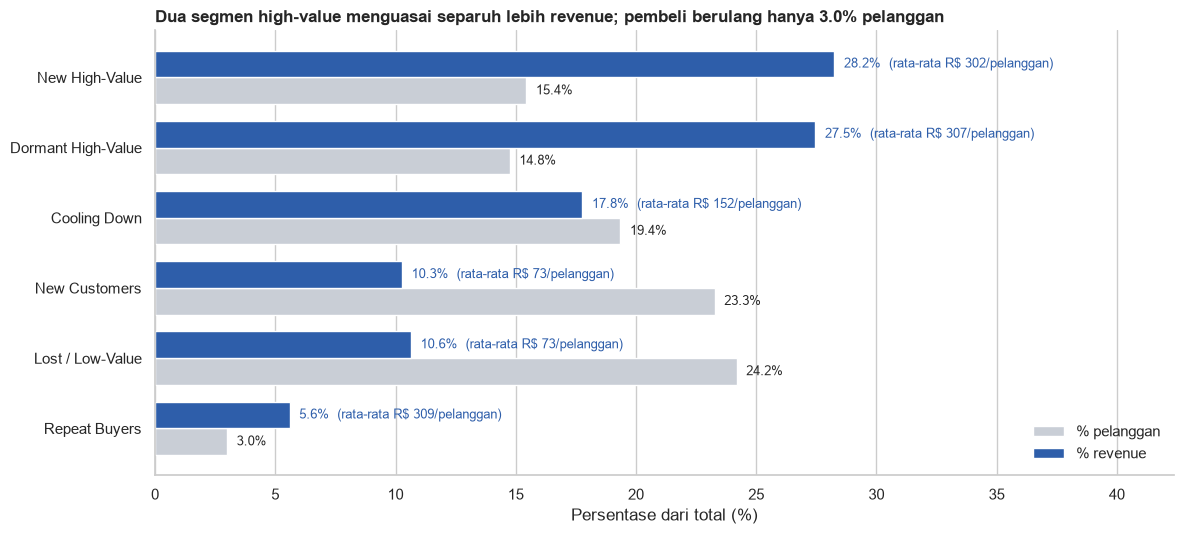

In [31]:
fig, ax = plt.subplots(figsize=(12, 5.5))
y = np.arange(len(seg)); h = 0.38
ax.barh(y + h/2, seg["pct_customers"], h, color=GREY, label="% pelanggan")
ax.barh(y - h/2, seg["pct_revenue"], h, color=BLUE, label="% revenue")
for i, (pc, pr, avg) in enumerate(zip(seg["pct_customers"], seg["pct_revenue"], seg["avg_monetary"])):
    ax.text(pc + 0.4, i + h/2, f"{pc:.1f}%", va="center", fontsize=9)
    ax.text(pr + 0.4, i - h/2, f"{pr:.1f}%  (rata-rata R$ {avg:,.0f}/pelanggan)", va="center", fontsize=9, color=BLUE)
ax.set_yticks(y); ax.set_yticklabels(seg.index); ax.invert_yaxis()
ax.set_xlim(0, max(seg["pct_revenue"].max(), seg["pct_customers"].max()) * 1.5)
ax.set_xlabel("Persentase dari total (%)")
ax.set_title("Dua segmen high-value menguasai separuh lebih revenue; pembeli berulang hanya {:.1f}% pelanggan".format(
    seg.loc["Repeat Buyers", "pct_customers"]), loc="left", fontsize=12)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

**Insight Visualisasi Pertanyaan 3**
- Chart memperlihatkan ketimpangan antara porsi pelanggan dan porsi revenue. Dua segmen **high-value** menyumbang **55,7%** revenue dari hanya 30,2% pelanggan:
  - **New High-Value** (15,4% pelanggan, 28,2% revenue): baru belanja (rata-rata 92 hari lalu), peluang terbaik untuk mendorong pembelian kedua.
  - **Dormant High-Value** (14,8% pelanggan, 27,5% revenue): rata-rata 392 hari tidak belanja, kandidat utama kampanye win-back.
- **Cooling Down** (19,4% pelanggan, 17,8% revenue) berada di ambang hilang. **New Customers** (23,3% / 10,3%) dan **Lost / Low-Value** (24,2% / 10,6%) adalah segmen terbesar dari sisi jumlah tetapi kecil dari sisi revenue (rata-rata belanja R$ 73), sehingga tidak layak diberi insentif mahal.
- **Repeat Buyers** hanya 3,0% pelanggan tetapi menyumbang 5,6% revenue.
- Catatan: "revenue" pada RFM memakai nilai belanja pelanggan (harga + ongkir), total R$ 15,37 juta, sehingga lebih besar dari revenue produk pada Pertanyaan 1.

## Analisis Lanjutan (Opsional)

Teknik analisis lanjutan yang dipakai (tanpa algoritma machine learning), masing-masing dipilih karena relevan dengan data transaksi e-commerce:

1. **RFM Analysis**: mengelompokkan pelanggan unik berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total belanja = harga + ongkir). Tujuannya menjawab Pertanyaan 3; perhitungannya ada di bagian EDA Pertanyaan 3 dan visualisasinya di bagian Visualization Pertanyaan 3.
2. **Binning / Manual Grouping**: dipakai pada keterlambatan (interval hari) di EDA Pertanyaan 2, pada skor Frequency dan aturan segmen RFM, serta pada pengelompokan state ke wilayah di bawah.
3. **Geospatial Analysis** (di bawah): memetakan sebaran pelanggan dan keterlambatan berdasarkan koordinat zip code. Tujuannya melihat apakah keterlambatan memiliki pola geografis, sebagai pendukung Pertanyaan 2.

### Geospatial Analysis

Koordinat tiap pelanggan diambil dari rata-rata lat/lng per zip code prefix (hasil cleaning geolocation). Panel kiri menunjukkan **kepadatan pelanggan**, panel kanan menunjukkan **tingkat keterlambatan per state** (ukuran lingkaran = jumlah pesanan, warna = late rate). Titik state adalah rata-rata koordinat pelanggan di state tersebut.

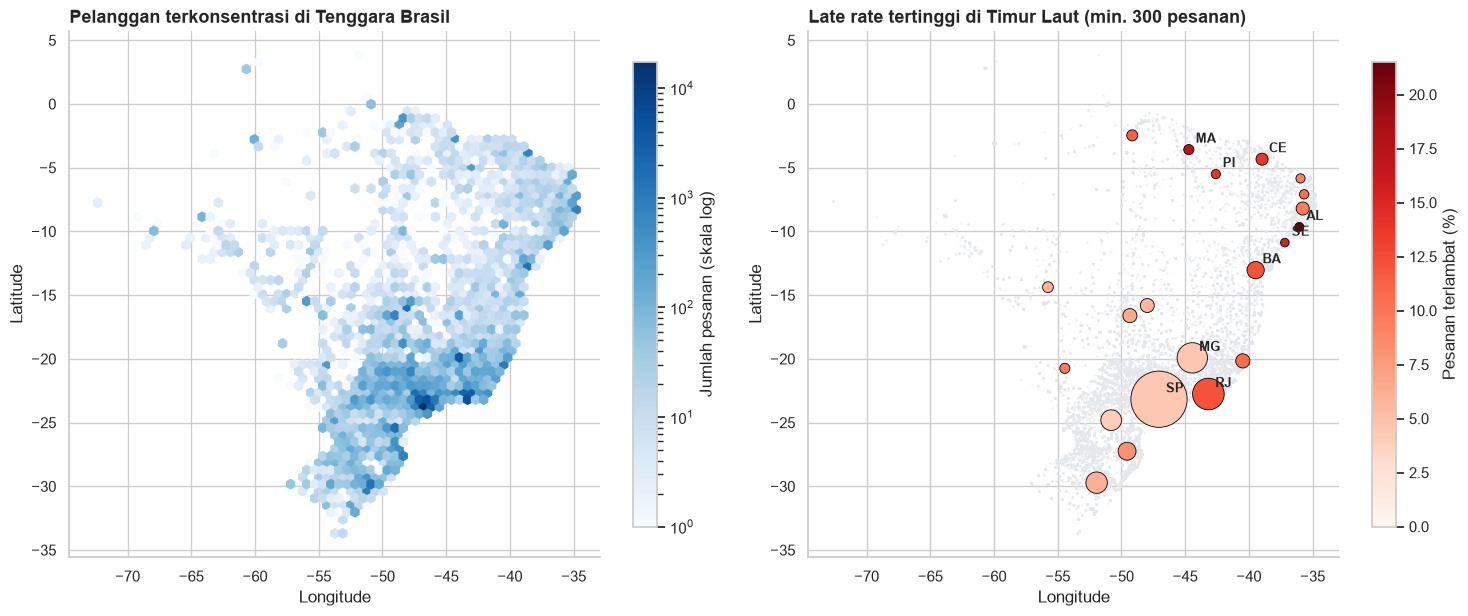

In [32]:
geo_orders = order_df.dropna(subset=["lat", "lng"])
state_geo = (geo_orders.groupby("customer_state")
             .agg(lat=("lat", "mean"), lng=("lng", "mean"), orders=("order_id", "nunique"), late_rate=("is_late", "mean"))
             .assign(late_rate=lambda x: x["late_rate"] * 100))
state_geo = state_geo[state_geo["orders"] >= 300]   # state kecil tidak stabil, konsisten dengan Pertanyaan 2

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

ax = axes[0]
hb = ax.hexbin(geo_orders["lng"], geo_orders["lat"], gridsize=60, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax, label="Jumlah pesanan (skala log)", shrink=0.7)
ax.set_title("Pelanggan terkonsentrasi di Tenggara Brasil", loc="left")

ax = axes[1]
ax.scatter(geo_orders["lng"], geo_orders["lat"], s=1, color="#E4E7EC", alpha=0.4)
sc = ax.scatter(state_geo["lng"], state_geo["lat"], s=state_geo["orders"] / 25 + 25, c=state_geo["late_rate"],
                cmap="Reds", edgecolor="black", linewidth=0.6, vmin=0, vmax=state_geo["late_rate"].max())
fig.colorbar(sc, ax=ax, label="Pesanan terlambat (%)", shrink=0.7)
for s_, r in state_geo.iterrows():
    if r["late_rate"] >= 12 or r["orders"] > 10000:
        ax.annotate(s_, (r["lng"], r["lat"]), xytext=(5, 5), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_title("Late rate tertinggi di Timur Laut (min. 300 pesanan)", loc="left")

for ax in axes:
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [33]:
# Late rate berdasarkan wilayah (pengelompokan manual state -> region)
region_map = {"SP": "Tenggara", "RJ": "Tenggara", "MG": "Tenggara", "ES": "Tenggara",
              "PR": "Selatan", "SC": "Selatan", "RS": "Selatan",
              "DF": "Tengah-Barat", "GO": "Tengah-Barat", "MT": "Tengah-Barat", "MS": "Tengah-Barat",
              "BA": "Timur Laut", "SE": "Timur Laut", "AL": "Timur Laut", "PE": "Timur Laut", "PB": "Timur Laut",
              "RN": "Timur Laut", "CE": "Timur Laut", "PI": "Timur Laut", "MA": "Timur Laut",
              "PA": "Utara", "AM": "Utara", "AP": "Utara", "AC": "Utara", "RO": "Utara", "RR": "Utara", "TO": "Utara"}
order_df = order_df.assign(region=order_df["customer_state"].map(region_map))
region = (order_df.groupby("region")
          .agg(orders=("order_id", "nunique"), late_rate=("is_late", "mean"), avg_review=("review_score", "mean"),
               median_delivery_days=("delivery_days", "median"))
          .assign(late_rate=lambda x: x["late_rate"] * 100).sort_values("late_rate", ascending=False))
region.round(2)

,orders,late_rate,avg_review,median_delivery_days
region,,,,
Timur Laut,9015,12.76,3.97,17.0
Utara,1791,8.60,4.03,20.0
Tengah-Barat,5610,6.54,4.13,13.0
Tenggara,66020,6.13,4.18,8.0
Selatan,13767,5.92,4.19,12.0


**Insight Geospatial Analysis**
- Pelanggan sangat terpusat di Tenggara Brasil: wilayah ini menyumbang 66.020 dari 96.203 pesanan (68,6%), dengan SP, RJ, dan MG sebagai titik terpadat.
- **Timur Laut punya late rate 12,8%, sekitar dua kali lipat Tenggara (6,1%) dan Selatan (5,9%)**, dengan median pengiriman 17 hari dibanding 8 hari di Tenggara.
- Wilayah Utara paling lama (median 20 hari) tetapi late rate-nya (8,6%) lebih rendah dari Timur Laut. Ini mengindikasikan estimasi pengiriman di Utara lebih longgar, sedangkan estimasi di Timur Laut tampak terlalu optimistis. Dugaan ini perlu diverifikasi dengan data estimasi per rute.
- RJ (Tenggara) menonjol sebagai pengecualian: dekat dengan pusat pelanggan, tetapi late rate 12,1%. Jadi keterlambatan tidak hanya berkaitan dengan jarak.

## Conclusion

### Kesimpulan Pertanyaan 1 (Produk & Revenue)
Pada Jan 2017 - Agu 2018, **10 dari 74 kategori menyumbang 62,5% revenue** (R$ 8,23 juta dari R$ 13,18 juta). Kontribusi dan pertumbuhan (Jan-Agu 2018 vs Jan-Agu 2017) masing-masing kategori:

| Peringkat | Kategori | Kontribusi revenue | Pertumbuhan |
|---|---|---|---|
| 1 | `health_beauty` | 9,3% | +210% |
| 2 | `watches_gifts` | 8,8% | +242% |
| 3 | `bed_bath_table` | 7,8% | +109% |
| 4 | `sports_leisure` | 7,2% | +139% |
| 5 | `computers_accessories` | 6,7% | +131% |
| 6 | `furniture_decor` | 5,4% | +123% |
| 7 | `housewares` | 4,7% | +207% |
| 8 | `cool_stuff` | 4,6% | +10% |
| 9 | `auto` | 4,4% | +174% |
| 10 | `garden_tools` | 3,6% | +54% |

Total revenue tumbuh **141%**, dan 8 dari 10 kategori tumbuh di atas 100%. Kategori yang paling layak diprioritaskan adalah kategori dengan kontribusi besar sekaligus pertumbuhan tinggi (`health_beauty`, `watches_gifts`, `housewares`, `auto`), sedangkan `cool_stuff` dan `garden_tools` tertinggal jauh.

### Kesimpulan Pertanyaan 2 (Pengiriman & Kepuasan)
**6,79% pesanan tiba setelah tanggal estimasi**. Pesanan terlambat mendapat rata-rata review **2,27** dibanding **4,29** untuk pesanan tepat waktu (selisih **2,02 poin**). Review sudah turun ke 3,73 pada pesanan yang telat 1 hari dan terus menurun hingga 1,70 pada pesanan yang telat lebih dari 7 hari. Lima state dengan late rate tertinggi adalah **AL (21,5%), MA (17,5%), SE (15,4%), PI (13,9%), dan CE (13,8%)**, semuanya di Timur Laut; wilayah ini memiliki late rate 12,8%, sekitar dua kali Tenggara dan Selatan. Maka wilayah prioritas evaluasi logistik adalah Timur Laut.

### Kesimpulan Pertanyaan 3 (Segmentasi Pelanggan)
Persen pelanggan dan persen revenue setiap segmen RFM:

| Segmen | % pelanggan | % revenue |
|---|---|---|
| New High-Value | 15,4% | 28,2% |
| Dormant High-Value | 14,8% | 27,5% |
| Cooling Down | 19,4% | 17,8% |
| New Customers | 23,3% | 10,3% |
| Lost / Low-Value | 24,2% | 10,6% |
| Repeat Buyers | 3,0% | 5,6% |

Hanya 3,0% pelanggan yang berbelanja ulang. Dua segmen high-value menyumbang 55,7% revenue dari 30,2% pelanggan, sehingga keduanya menjadi target utama kampanye retensi: **Dormant High-Value** (13.733 pelanggan, rata-rata 392 hari sejak belanja terakhir) untuk win-back, dan **New High-Value** (14.377 pelanggan) untuk mendorong pembelian kedua.

### Rekomendasi (Action Items)
1. **Prioritaskan stok dan promosi pada kategori inti yang tumbuh.** Alokasikan stok dan anggaran promosi terbesar untuk `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories` (39,9% revenue), dengan perhatian khusus pada `housewares` dan `auto` yang tumbuh di atas 170%. Evaluasi `cool_stuff` dan `garden_tools` yang tertinggal (harga, ketersediaan, atau kualitas listing). Siapkan kapasitas gudang dan kurir sebelum November, saat lonjakan permintaan terjadi.
2. **Benahi logistik di Timur Laut.** Evaluasi mitra kurir dan rute ke AL, MA, SE, PI, dan CE, serta tinjau ulang perhitungan estimasi tiba agar lebih realistis, dengan target late rate wilayah ini mendekati rata-rata nasional (6,8%). Karena rata-rata review sudah turun dari 4,03 (tiba di hari estimasi) menjadi 3,73 ketika pesanan telat 1 hari, kirim notifikasi proaktif kepada pelanggan sebelum tanggal estimasi terlewati bila pesanan berisiko terlambat.
3. **Jalankan kampanye retensi bertarget berdasarkan segmen RFM.** Win-back dengan voucher untuk *Dormant High-Value*, program pembelian kedua dalam 90 hari pertama untuk *New High-Value*, dan pengingat atau penawaran terbatas untuk *Cooling Down*. Hindari insentif mahal untuk *New Customers* dan *Lost / Low-Value* (rata-rata belanja R$ 73).

*Keterbatasan:* analisis hanya mencakup pesanan `delivered` pada Jan 2017 - Agu 2018 dan bersifat deskriptif (agregasi), jadi hubungan yang ditemukan bukan bukti sebab-akibat.